In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/01301.png
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/00929.png
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/00704.png
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/01124.png
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/01570.png
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Si

In [2]:
# ============================================================
# NB2 — CELL 1
# Imports, environment, reproducibility, and output folder
# No pip installation is used.
# ============================================================

from __future__ import annotations

import hashlib
import importlib
import json
import os
import random
import sys
import textwrap
import time

from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault(
    "NO_ALBUMENTATIONS_UPDATE",
    "1",
)

os.environ.setdefault(
    "TOKENIZERS_PARALLELISM",
    "false",
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import Markdown, display
from PIL import Image
from torch.utils.data import DataLoader
from tqdm.auto import tqdm


try:
    import transformers

    from transformers import (
        SegformerForSemanticSegmentation,
    )

except ImportError as error:
    raise RuntimeError(
        "The transformers package is not available in this "
        "Kaggle runtime. This notebook does not install packages. "
        "Use a Kaggle environment that already contains transformers."
    ) from error


SEED = 42

INPUT_ROOT = Path(
    "/kaggle/input"
)

OUTPUT_ROOT = Path(
    "/kaggle/working/NB2_outputs"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


def seed_everything(
    seed: int,
) -> None:

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)


DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)


if hasattr(
    torch,
    "set_float32_matmul_precision",
):
    torch.set_float32_matmul_precision(
        "high"
    )


print(
    "Python:",
    sys.version.split()[0],
)

print(
    "PyTorch:",
    torch.__version__,
)

print(
    "Transformers:",
    transformers.__version__,
)

print(
    "Device:",
    DEVICE,
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print(
    "Output folder:",
    OUTPUT_ROOT,
)

Python: 3.12.13
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Device: cuda
GPU: Tesla T4
Output folder: /kaggle/working/NB2_outputs


In [3]:
# ============================================================
# NB2 — CELL 2
# Locate the original dataset and NB0 outputs.
# Load the identical leakage-safe split from NB0.
# No new split is generated.
# ============================================================

print(
    "Attached Kaggle inputs:"
)

for path in sorted(
    INPUT_ROOT.iterdir()
):
    print(
        " -",
        path,
    )


def find_dataset_root(
    input_root: Path,
) -> Path:

    candidates = set()

    for training_directory in input_root.rglob(
        "training"
    ):
        candidate_root = (
            training_directory.parent
        )

        required_directories = [
            candidate_root
            / "training"
            / "images",

            candidate_root
            / "training"
            / "masks",

            candidate_root
            / "testing"
            / "images",

            candidate_root
            / "testing"
            / "masks",
        ]

        if all(
            path.is_dir()
            for path in required_directories
        ):
            candidates.add(
                candidate_root
            )

    if not candidates:
        raise FileNotFoundError(
            "The original Moroccan dataset was not found. "
            "Add it as a Kaggle input. Required folders: "
            "training/images, training/masks, "
            "testing/images and testing/masks."
        )

    return sorted(
        candidates,

        key=lambda path: (
            "moroccan"
            not in str(path).lower(),

            len(
                str(path)
            ),

            str(path),
        ),
    )[0]


# ------------------------------------------------------------
# Locate NB0 output
# ------------------------------------------------------------

split_candidates = sorted(
    INPUT_ROOT.rglob(
        "all_splits.csv"
    )
)


if not split_candidates:
    raise FileNotFoundError(
        "NB0 all_splits.csv was not found. "
        "Add the saved NB0 notebook output "
        "as a Kaggle input."
    )


split_candidates = sorted(
    split_candidates,

    key=lambda path: (
        "NB0_outputs"
        not in str(path),

        len(
            str(path)
        ),
    ),
)


SPLIT_FILE = (
    split_candidates[0]
)

NB0_OUTPUT_ROOT = (
    SPLIT_FILE.parents[1]
)

COMMON_DIR = (
    NB0_OUTPUT_ROOT
    / "common"
)

CLASS_INFO_FILE = (
    NB0_OUTPUT_ROOT
    / "metadata"
    / "class_info.json"
)

CLASS_DISTRIBUTION_FILE = (
    NB0_OUTPUT_ROOT
    / "metadata"
    / "training_class_distribution.csv"
)

COMPARISON_IDS_FILE = (
    NB0_OUTPUT_ROOT
    / "comparison_sample_ids.json"
)


DATA_ROOT = find_dataset_root(
    INPUT_ROOT
)


required_nb0_files = [
    COMMON_DIR
    / "segmentation_common.py",

    CLASS_INFO_FILE,

    CLASS_DISTRIBUTION_FILE,

    COMPARISON_IDS_FILE,
]


for required_path in (
    required_nb0_files
):
    if not required_path.exists():
        raise FileNotFoundError(
            f"Missing NB0 artifact: "
            f"{required_path}"
        )


# ------------------------------------------------------------
# Load class information from NB0
# ------------------------------------------------------------

with CLASS_INFO_FILE.open(
    "r",
    encoding="utf-8",
) as file:

    class_info = json.load(
        file
    )


NUM_CLASSES = int(
    class_info[
        "num_classes"
    ]
)

IMAGE_SIZE = int(
    class_info[
        "image_size"
    ][0]
)


CLASS_ID_TO_NAME = {
    int(class_id): class_name

    for class_id, class_name
    in class_info[
        "class_names"
    ].items()
}


CLASS_NAME_TO_ID = {
    class_name: class_id

    for class_id, class_name
    in CLASS_ID_TO_NAME.items()
}


if CLASS_ID_TO_NAME != {
    0: "background",
    1: "landing_site",
}:
    raise RuntimeError(
        "Unexpected NB0 class mapping: "
        f"{CLASS_ID_TO_NAME}"
    )


# ------------------------------------------------------------
# Calculate split fingerprint
# ------------------------------------------------------------

def file_sha256(
    path: Path,
) -> str:

    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as file:

        while chunk := file.read(
            1024 * 1024
        ):
            digest.update(
                chunk
            )

    return digest.hexdigest()


SPLIT_SHA256 = file_sha256(
    SPLIT_FILE
)


# ------------------------------------------------------------
# Load and verify the manifest
# ------------------------------------------------------------

split_df = pd.read_csv(
    SPLIT_FILE
)


required_columns = {
    "image_id",
    "split",
    "image_relpath",
    "encoded_mask_relpath",
    "group_id",
}


missing_columns = (
    required_columns
    - set(
        split_df.columns
    )
)


if missing_columns:
    raise RuntimeError(
        "NB0 manifest is missing: "
        f"{sorted(missing_columns)}"
    )


expected_counts = {
    "train": 1416,
    "val": 314,
    "test": 360,
}


actual_counts = (
    split_df[
        "split"
    ]
    .value_counts()
    .to_dict()
)


assert len(split_df) == 2090, (
    f"Expected 2,090 rows, "
    f"found {len(split_df)}"
)


assert split_df[
    "image_id"
].is_unique, (
    "Duplicate image_id found."
)


assert actual_counts == expected_counts, (
    f"Expected {expected_counts}, "
    f"found {actual_counts}"
)


assert (
    split_df.groupby(
        "group_id"
    )["split"]
    .nunique()
    .max()
    == 1
), (
    "A relationship group crosses split boundaries."
)


# ------------------------------------------------------------
# Verify image and encoded-mask paths
# ------------------------------------------------------------

split_df[
    "resolved_image_path"
] = split_df[
    "image_relpath"
].apply(
    lambda relative_path:
    str(
        DATA_ROOT
        / relative_path
    )
)


split_df[
    "resolved_mask_path"
] = split_df[
    "encoded_mask_relpath"
].apply(
    lambda relative_path:
    str(
        NB0_OUTPUT_ROOT
        / relative_path
    )
)


missing_images = [
    path

    for path
    in split_df[
        "resolved_image_path"
    ]

    if not Path(path).exists()
]


missing_masks = [
    path

    for path
    in split_df[
        "resolved_mask_path"
    ]

    if not Path(path).exists()
]


if missing_images:
    raise FileNotFoundError(
        "Missing raw images. Examples: "
        f"{missing_images[:3]}"
    )


if missing_masks:
    raise FileNotFoundError(
        "Missing encoded masks. Examples: "
        f"{missing_masks[:3]}"
    )


train_df = (
    split_df[
        split_df["split"]
        == "train"
    ]
    .reset_index(
        drop=True
    )
)


val_df = (
    split_df[
        split_df["split"]
        == "val"
    ]
    .reset_index(
        drop=True
    )
)


test_df = (
    split_df[
        split_df["split"]
        == "test"
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\nRaw dataset root:",
    DATA_ROOT,
)

print(
    "NB0 output root:",
    NB0_OUTPUT_ROOT,
)

print(
    "Split file:",
    SPLIT_FILE,
)

print(
    "Split SHA-256:",
    SPLIT_SHA256,
)

print(
    "Classes:",
    CLASS_ID_TO_NAME,
)

print(
    "Image size:",
    IMAGE_SIZE,
)


display(
    pd.DataFrame(
        {
            "split": [
                "train",
                "validation",
                "test",
            ],

            "samples": [
                len(train_df),
                len(val_df),
                len(test_df),
            ],
        }
    )
)


print(
    "Identical NB0 split loaded. "
    "NB2 created no new split."
)

Attached Kaggle inputs:
 - /kaggle/input/datasets
 - /kaggle/input/notebooks

Raw dataset root: /kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset
NB0 output root: /kaggle/input/notebooks/happysruti/cse438-01/NB0_outputs
Split file: /kaggle/input/notebooks/happysruti/cse438-01/NB0_outputs/splits/all_splits.csv
Split SHA-256: 1867384ab21b0acbedb0b96721d42355ee6a55e56a2874bf52e9b628264b0d59
Classes: {0: 'background', 1: 'landing_site'}
Image size: 256


,split,samples
0,train,1416
1,validation,314
2,test,360


Identical NB0 split loaded. NB2 created no new split.


In [4]:
# ============================================================
# TASK E — CELL 3
# Complete configuration, NB0 datasets, transforms and loaders
# ============================================================

CONFIG = {
    "notebook": "NB2",

    "model": "SegFormer-B0",

    "encoder": "MiT-B0",

    "pretrained_checkpoint": (
        "nvidia/"
        "segformer-b0-finetuned-ade-512-512"
    ),

    "pretrained_domain": "ADE20K",

    "ignore_mismatched_sizes": True,

    "seed": SEED,

    "image_size": IMAGE_SIZE,

    "num_classes": NUM_CLASSES,

    "batch_size": 16,

    "num_workers": 0,

    "minimum_epochs": 50,

    "maximum_epochs": 60,

    "post_minimum_patience": 5,

    "optimizer": "AdamW",

    "learning_rate": 6e-5,

    "weight_decay": 1e-2,

    "scheduler": "CosineAnnealingLR",

    "loss": (
        "weighted_cross_entropy "
        "+ 1.0*dice_loss"
    ),

    "dice_loss_weight": 1.0,

    "gradient_clip_norm": 1.0,

    "mixed_precision": USE_AMP,

    "checkpoint_selection": (
        "highest validation mIoU"
    ),

    "class_weight_source": (
        "NB0 training pixels only"
    ),

    "split_file": str(
        SPLIT_FILE
    ),

    "split_sha256": (
        SPLIT_SHA256
    ),

    "nb0_output_root": str(
        NB0_OUTPUT_ROOT
    ),

    "raw_dataset_root": str(
        DATA_ROOT
    ),

    "torch_version": (
        torch.__version__
    ),

    "transformers_version": (
        transformers.__version__
    ),
}


display(
    pd.DataFrame(
        {
            "hyperparameter": list(
                CONFIG.keys()
            ),

            "value": [
                str(value)

                for value
                in CONFIG.values()
            ],
        }
    )
)


# ------------------------------------------------------------
# Import shared preprocessing from NB0
# ------------------------------------------------------------

if str(
    COMMON_DIR
) not in sys.path:

    sys.path.insert(
        0,
        str(COMMON_DIR),
    )


importlib.invalidate_caches()


import segmentation_common


importlib.reload(
    segmentation_common
)


from segmentation_common import (
    LandingSiteDataset,
    build_eval_transform,
    build_train_transform,
    load_mask,
)


# Exact training augmentation pipeline from NB0
train_transform = (
    build_train_transform(
        image_size=IMAGE_SIZE
    )
)


# Deterministic validation/test transform from NB0
eval_transform = (
    build_eval_transform(
        image_size=IMAGE_SIZE
    )
)


train_dataset = LandingSiteDataset(
    train_df,

    raw_dataset_root=DATA_ROOT,

    nb0_output_root=NB0_OUTPUT_ROOT,

    transform=train_transform,

    return_id=True,
)


val_dataset = LandingSiteDataset(
    val_df,

    raw_dataset_root=DATA_ROOT,

    nb0_output_root=NB0_OUTPUT_ROOT,

    transform=eval_transform,

    return_id=True,
)


test_dataset = LandingSiteDataset(
    test_df,

    raw_dataset_root=DATA_ROOT,

    nb0_output_root=NB0_OUTPUT_ROOT,

    transform=eval_transform,

    return_id=True,
)


PIN_MEMORY = (
    DEVICE.type == "cuda"
)


train_loader = DataLoader(
    train_dataset,

    batch_size=CONFIG[
        "batch_size"
    ],

    shuffle=True,

    num_workers=CONFIG[
        "num_workers"
    ],

    pin_memory=PIN_MEMORY,

    drop_last=False,
)


val_loader = DataLoader(
    val_dataset,

    batch_size=CONFIG[
        "batch_size"
    ],

    shuffle=False,

    num_workers=CONFIG[
        "num_workers"
    ],

    pin_memory=PIN_MEMORY,

    drop_last=False,
)


test_loader = DataLoader(
    test_dataset,

    batch_size=CONFIG[
        "batch_size"
    ],

    shuffle=False,

    num_workers=CONFIG[
        "num_workers"
    ],

    pin_memory=PIN_MEMORY,

    drop_last=False,
)


sample_images, sample_masks, sample_ids = (
    next(
        iter(train_loader)
    )
)


print(
    "Train batch image shape:",
    tuple(
        sample_images.shape
    ),
)

print(
    "Train batch mask shape:",
    tuple(
        sample_masks.shape
    ),
)

print(
    "Mask values:",
    torch.unique(
        sample_masks
    ).tolist(),
)

print(
    "Example IDs:",
    list(
        sample_ids[:3]
    ),
)

,hyperparameter,value
0,notebook,NB2
1,model,SegFormer-B0
2,encoder,MiT-B0
3,pretrained_checkpoint,nvidia/segformer-b0-finetuned-ade-512-512
4,pretrained_domain,ADE20K
5,ignore_mismatched_sizes,True
6,seed,42
7,image_size,256
8,num_classes,2
9,batch_size,16


Train batch image shape: (16, 3, 256, 256)
Train batch mask shape: (16, 256, 256)
Mask values: [0, 1]
Example IDs: ['training_00299', 'training_01581', 'training_00286']


In [5]:
# ============================================================
# TASK E — CELL 4
# Load SegFormer-B0 and define loss, metrics and evaluation
# ============================================================

def find_local_segformer_b0(
    input_root: Path,
) -> Path | None:

    for config_path in input_root.rglob(
        "config.json"
    ):
        checkpoint_directory = (
            config_path.parent
        )

        has_model_weights = any(
            (
                checkpoint_directory
                / filename
            ).exists()

            for filename in [
                "model.safetensors",
                "pytorch_model.bin",
            ]
        )

        if not has_model_weights:
            continue

        try:
            payload = json.loads(
                config_path.read_text(
                    encoding="utf-8"
                )
            )

        except Exception:
            continue

        if payload.get(
            "model_type"
        ) != "segformer":
            continue

        hidden_sizes = payload.get(
            "hidden_sizes"
        )

        depths = payload.get(
            "depths"
        )

        if (
            hidden_sizes
            == [32, 64, 160, 256]

            and depths
            == [2, 2, 2, 2]
        ):
            return checkpoint_directory

    return None


# ------------------------------------------------------------
# Load local or online pretrained checkpoint
# ------------------------------------------------------------

local_checkpoint = (
    find_local_segformer_b0(
        INPUT_ROOT
    )
)


if local_checkpoint is not None:

    MODEL_SOURCE = str(
        local_checkpoint
    )

    model = (
        SegformerForSemanticSegmentation
        .from_pretrained(
            MODEL_SOURCE,

            num_labels=NUM_CLASSES,

            id2label=CLASS_ID_TO_NAME,

            label2id=CLASS_NAME_TO_ID,

            ignore_mismatched_sizes=True,

            local_files_only=True,
        )
    )

    print(
        "Loaded local SegFormer-B0 checkpoint:",
        MODEL_SOURCE,
    )


else:

    MODEL_SOURCE = CONFIG[
        "pretrained_checkpoint"
    ]

    try:
        model = (
            SegformerForSemanticSegmentation
            .from_pretrained(
                MODEL_SOURCE,

                num_labels=NUM_CLASSES,

                id2label=CLASS_ID_TO_NAME,

                label2id=CLASS_NAME_TO_ID,

                ignore_mismatched_sizes=True,
            )
        )

        print(
            "Loaded pretrained checkpoint:",
            MODEL_SOURCE,
        )

    except Exception as error:

        raise RuntimeError(
            "SegFormer-B0 weights could not be loaded. "
            "No pip installation is needed, but Kaggle Internet "
            "must be enabled for the first checkpoint download, "
            "or a local SegFormer-B0 checkpoint must be attached "
            "as a Kaggle input. Original error: "
            + repr(error)
        ) from error


model.config.semantic_loss_ignore_index = 255

model = model.to(
    DEVICE
)


TOTAL_PARAMETERS = sum(
    parameter.numel()

    for parameter
    in model.parameters()
)


TRAINABLE_PARAMETERS = sum(
    parameter.numel()

    for parameter
    in model.parameters()

    if parameter.requires_grad
)


CONFIG[
    "resolved_model_source"
] = MODEL_SOURCE

CONFIG[
    "total_parameters"
] = int(
    TOTAL_PARAMETERS
)

CONFIG[
    "trainable_parameters"
] = int(
    TRAINABLE_PARAMETERS
)


# ------------------------------------------------------------
# Training-only class weights from NB0
# ------------------------------------------------------------

class_distribution_df = (
    pd.read_csv(
        CLASS_DISTRIBUTION_FILE
    )
    .sort_values(
        "class_id"
    )
    .reset_index(
        drop=True
    )
)


class_weights = torch.tensor(
    class_distribution_df[
        "inverse_frequency_class_weight"
    ].values,

    dtype=torch.float32,

    device=DEVICE,
)


CONFIG[
    "class_weights"
] = [
    float(value)

    for value
    in class_weights
    .detach()
    .cpu()
    .tolist()
]


display(
    class_distribution_df
)


print(
    "Class weights:",
    CONFIG[
        "class_weights"
    ],
)

print(
    "Total parameters:",
    f"{TOTAL_PARAMETERS:,}",
)

print(
    "Trainable parameters:",
    f"{TRAINABLE_PARAMETERS:,}",
)


cross_entropy_loss = (
    nn.CrossEntropyLoss(
        weight=class_weights
    )
)


# ------------------------------------------------------------
# Loss functions
# ------------------------------------------------------------

def resize_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:

    if (
        logits.shape[-2:]
        == targets.shape[-2:]
    ):
        return logits

    return F.interpolate(
        logits,

        size=targets.shape[-2:],

        mode="bilinear",

        align_corners=False,
    )


def dice_loss_from_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
    epsilon: float = 1e-6,
) -> torch.Tensor:

    probabilities = torch.softmax(
        logits,
        dim=1,
    )

    one_hot = F.one_hot(
        targets,
        num_classes=NUM_CLASSES,
    )

    one_hot = (
        one_hot
        .permute(
            0,
            3,
            1,
            2,
        )
        .float()
    )

    dimensions = (
        0,
        2,
        3,
    )

    intersection = (
        probabilities
        * one_hot
    ).sum(
        dim=dimensions
    )

    cardinality = (
        probabilities
        + one_hot
    ).sum(
        dim=dimensions
    )

    dice = (
        2.0
        * intersection
        + epsilon
    ) / (
        cardinality
        + epsilon
    )

    return (
        1.0
        - dice.mean()
    )


def segmentation_loss(
    raw_logits: torch.Tensor,
    targets: torch.Tensor,
) -> tuple[
    torch.Tensor,
    torch.Tensor,
]:

    logits = resize_logits(
        raw_logits,
        targets,
    )

    cross_entropy = (
        cross_entropy_loss(
            logits,
            targets,
        )
    )

    dice = dice_loss_from_logits(
        logits,
        targets,
    )

    total_loss = (
        cross_entropy
        + CONFIG[
            "dice_loss_weight"
        ]
        * dice
    )

    return (
        total_loss,
        logits,
    )


# ------------------------------------------------------------
# Mixed precision helpers
# ------------------------------------------------------------

def autocast_context():

    if DEVICE.type != "cuda":
        return nullcontext()

    try:
        return torch.amp.autocast(
            "cuda",
            enabled=USE_AMP,
        )

    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def make_grad_scaler():

    if DEVICE.type != "cuda":
        return torch.cuda.amp.GradScaler(
            enabled=False
        )

    try:
        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except TypeError:
        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


# ------------------------------------------------------------
# Metric functions
# ------------------------------------------------------------

def batch_confusion_matrix(
    predictions: torch.Tensor,
    targets: torch.Tensor,
    num_classes: int = NUM_CLASSES,
) -> torch.Tensor:

    predictions = (
        predictions
        .detach()
        .reshape(-1)
        .cpu()
    )

    targets = (
        targets
        .detach()
        .reshape(-1)
        .cpu()
    )

    valid = (
        (targets >= 0)
        & (targets < num_classes)
    )

    encoded = (
        num_classes
        * targets[valid]
        + predictions[valid]
    )

    return torch.bincount(
        encoded,

        minlength=(
            num_classes ** 2
        ),
    ).reshape(
        num_classes,
        num_classes,
    )


def metrics_from_confusion_matrix(
    confusion: np.ndarray,
) -> dict:

    confusion = confusion.astype(
        np.float64
    )

    true_positive = np.diag(
        confusion
    )

    actual_pixels = confusion.sum(
        axis=1
    )

    predicted_pixels = confusion.sum(
        axis=0
    )

    union = (
        actual_pixels
        + predicted_pixels
        - true_positive
    )


    per_class_iou = np.divide(
        true_positive,
        union,

        out=np.zeros_like(
            true_positive
        ),

        where=union > 0,
    )


    per_class_accuracy = np.divide(
        true_positive,
        actual_pixels,

        out=np.zeros_like(
            true_positive
        ),

        where=actual_pixels > 0,
    )


    per_class_dice = np.divide(
        2.0
        * true_positive,

        actual_pixels
        + predicted_pixels,

        out=np.zeros_like(
            true_positive
        ),

        where=(
            actual_pixels
            + predicted_pixels
        ) > 0,
    )


    overall_pixel_accuracy = (
        true_positive.sum()
        / confusion.sum()

        if confusion.sum() > 0

        else 0.0
    )


    return {
        "mean_iou": float(
            np.mean(
                per_class_iou
            )
        ),

        "overall_pixel_accuracy": float(
            overall_pixel_accuracy
        ),

        "mean_pixel_accuracy": float(
            np.mean(
                per_class_accuracy
            )
        ),

        "mean_dice": float(
            np.mean(
                per_class_dice
            )
        ),

        "per_class_iou": {
            CLASS_ID_TO_NAME[index]:
            float(value)

            for index, value
            in enumerate(
                per_class_iou
            )
        },

        "per_class_accuracy": {
            CLASS_ID_TO_NAME[index]:
            float(value)

            for index, value
            in enumerate(
                per_class_accuracy
            )
        },

        "per_class_dice": {
            CLASS_ID_TO_NAME[index]:
            float(value)

            for index, value
            in enumerate(
                per_class_dice
            )
        },
    }


@torch.no_grad()
def evaluate_model(
    model: nn.Module,
    data_loader: DataLoader,
    split_name: str,
) -> tuple[
    dict,
    float,
    pd.DataFrame,
    np.ndarray,
]:

    model.eval()

    total_loss = 0.0
    total_samples = 0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
    )

    per_image_records = []


    for (
        images,
        masks,
        image_ids,
    ) in tqdm(
        data_loader,
        desc=f"Evaluate {split_name}",
    ):

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True,
        )


        with autocast_context():

            outputs = model(
                pixel_values=images
            )

            loss, logits = (
                segmentation_loss(
                    outputs.logits,
                    masks,
                )
            )


        predictions = torch.argmax(
            logits,
            dim=1,
        )


        batch_size = (
            images.shape[0]
        )

        total_loss += (
            float(
                loss.item()
            )
            * batch_size
        )

        total_samples += (
            batch_size
        )


        confusion += (
            batch_confusion_matrix(
                predictions,
                masks,
            )
        )


        for index, image_id in enumerate(
            image_ids
        ):

            image_confusion = (
                batch_confusion_matrix(
                    predictions[index],
                    masks[index],
                )
                .numpy()
            )

            image_metrics = (
                metrics_from_confusion_matrix(
                    image_confusion
                )
            )


            per_image_records.append(
                {
                    "image_id": image_id,

                    "split": split_name,

                    "mean_iou": (
                        image_metrics[
                            "mean_iou"
                        ]
                    ),

                    "landing_site_iou": (
                        image_metrics[
                            "per_class_iou"
                        ][
                            "landing_site"
                        ]
                    ),

                    "background_iou": (
                        image_metrics[
                            "per_class_iou"
                        ][
                            "background"
                        ]
                    ),

                    "mean_dice": (
                        image_metrics[
                            "mean_dice"
                        ]
                    ),
                }
            )


    confusion_numpy = (
        confusion.numpy()
    )

    metrics = (
        metrics_from_confusion_matrix(
            confusion_numpy
        )
    )

    average_loss = (
        total_loss
        / max(
            total_samples,
            1,
        )
    )

    per_image_dataframe = (
        pd.DataFrame(
            per_image_records
        )
    )


    return (
        metrics,
        average_loss,
        per_image_dataframe,
        confusion_numpy,
    )


# ------------------------------------------------------------
# Confirm SegFormer output size
# ------------------------------------------------------------

with torch.no_grad():

    example_outputs = model(
        pixel_values=(
            sample_images[:2]
            .to(DEVICE)
        )
    )


print(
    "Raw SegFormer logits shape:",
    tuple(
        example_outputs.logits.shape
    ),
)

print(
    "Ground-truth mask shape:",
    tuple(
        sample_masks[:2].shape
    ),
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Loaded pretrained checkpoint: nvidia/segformer-b0-finetuned-ade-512-512


,class_id,class_name,training_pixel_count,training_pixel_percent,inverse_frequency_class_weight
0,0,background,64478549,69.481962,0.719611
1,1,landing_site,28320427,30.518038,1.638375


Class weights: [0.7196112275123596, 1.6383752822875977]
Total parameters: 3,714,658
Trainable parameters: 3,714,658
Raw SegFormer logits shape: (2, 2, 64, 64)
Ground-truth mask shape: (2, 256, 256)


In [6]:
# ============================================================
# TASK E — CELL 5
# Train SegFormer-B0 for at least 50 epochs
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),

    lr=CONFIG[
        "learning_rate"
    ],

    weight_decay=CONFIG[
        "weight_decay"
    ],
)


scheduler = (
    torch.optim.lr_scheduler
    .CosineAnnealingLR(
        optimizer,

        T_max=CONFIG[
            "maximum_epochs"
        ],
    )
)


scaler = make_grad_scaler()


def train_one_epoch(
    model: nn.Module,
    data_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    epoch: int,
) -> float:

    model.train()

    running_loss = 0.0
    total_samples = 0


    progress = tqdm(
        data_loader,
        desc=f"Train epoch {epoch:02d}",
    )


    for (
        images,
        masks,
        _,
    ) in progress:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True,
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with autocast_context():

            outputs = model(
                pixel_values=images
            )

            loss, _ = (
                segmentation_loss(
                    outputs.logits,
                    masks,
                )
            )


        scaler.scale(
            loss
        ).backward()


        scaler.unscale_(
            optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),

            max_norm=CONFIG[
                "gradient_clip_norm"
            ],
        )


        scaler.step(
            optimizer
        )

        scaler.update()


        batch_size = (
            images.shape[0]
        )

        running_loss += (
            float(
                loss.item()
            )
            * batch_size
        )

        total_samples += (
            batch_size
        )


        progress.set_postfix(
            loss=(
                running_loss
                / max(
                    total_samples,
                    1,
                )
            )
        )


    return (
        running_loss
        / max(
            total_samples,
            1,
        )
    )


history = []

best_val_miou = -1.0
best_epoch = 0

epochs_since_improvement = 0


best_checkpoint_path = (
    OUTPUT_ROOT
    / "segformer_b0_best.pth"
)

last_checkpoint_path = (
    OUTPUT_ROOT
    / "segformer_b0_last.pth"
)

history_path = (
    OUTPUT_ROOT
    / "segformer_b0_training_history.csv"
)


training_start_time = (
    time.time()
)


for epoch in range(
    1,
    CONFIG[
        "maximum_epochs"
    ] + 1,
):

    current_learning_rate = (
        optimizer.param_groups[
            0
        ]["lr"]
    )


    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        epoch,
    )


    (
        validation_metrics,
        validation_loss,
        _,
        _,
    ) = evaluate_model(
        model,
        val_loader,
        "val",
    )


    history.append(
        {
            "epoch": epoch,

            "train_loss": (
                train_loss
            ),

            "val_loss": (
                validation_loss
            ),

            "val_mIoU": (
                validation_metrics[
                    "mean_iou"
                ]
            ),

            "val_overall_pixel_accuracy": (
                validation_metrics[
                    "overall_pixel_accuracy"
                ]
            ),

            "val_mean_pixel_accuracy": (
                validation_metrics[
                    "mean_pixel_accuracy"
                ]
            ),

            "val_mean_dice": (
                validation_metrics[
                    "mean_dice"
                ]
            ),

            "learning_rate": (
                current_learning_rate
            ),
        }
    )


    history_df = pd.DataFrame(
        history
    )


    history_df.to_csv(
        history_path,
        index=False,
    )


    improved = (
        validation_metrics[
            "mean_iou"
        ]
        > best_val_miou
    )


    checkpoint_payload = {
        "epoch": epoch,

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "config": CONFIG,

        "val_metrics": (
            validation_metrics
        ),
    }


    if improved:

        best_val_miou = (
            validation_metrics[
                "mean_iou"
            ]
        )

        best_epoch = (
            epoch
        )

        epochs_since_improvement = 0


        torch.save(
            checkpoint_payload,
            best_checkpoint_path,
        )


    else:

        epochs_since_improvement += 1


    torch.save(
        checkpoint_payload,
        last_checkpoint_path,
    )


    print(
        f"Epoch {epoch:02d}/"
        f"{CONFIG['maximum_epochs']} | "

        f"train loss="
        f"{train_loss:.4f} | "

        f"val loss="
        f"{validation_loss:.4f} | "

        f"val mIoU="
        f"{validation_metrics['mean_iou']:.4f} | "

        f"val Dice="
        f"{validation_metrics['mean_dice']:.4f} | "

        f"lr="
        f"{current_learning_rate:.8f}"
    )


    scheduler.step()


    if (
        epoch
        >= CONFIG[
            "minimum_epochs"
        ]

        and epochs_since_improvement
        >= CONFIG[
            "post_minimum_patience"
        ]
    ):

        print(
            "Minimum 50 epochs completed. "
            "Validation mIoU has not improved for "
            f"{epochs_since_improvement} epochs, "
            "so training stops."
        )

        break


training_time_minutes = (
    time.time()
    - training_start_time
) / 60.0


history_df = pd.DataFrame(
    history
)


actual_trained_epochs = int(
    history_df[
        "epoch"
    ].max()
)


CONFIG[
    "actual_trained_epochs"
] = actual_trained_epochs

CONFIG[
    "best_epoch"
] = int(
    best_epoch
)

CONFIG[
    "best_validation_miou"
] = float(
    best_val_miou
)

CONFIG[
    "training_time_minutes"
] = float(
    training_time_minutes
)

CONFIG[
    "saved_at"
] = datetime.now(
    timezone.utc
).isoformat()


with (
    OUTPUT_ROOT
    / "segformer_b0_config.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        CONFIG,
        file,
        indent=2,
    )


print(
    f"Training time: "
    f"{training_time_minutes:.2f} minutes"
)

print(
    "Actual epochs:",
    actual_trained_epochs,
)

print(
    f"Best validation mIoU: "
    f"{best_val_miou:.4f} "
    f"at epoch {best_epoch}"
)

print(
    "Best checkpoint:",
    best_checkpoint_path,
)


display(
    history_df.tail()
)

Train epoch 01:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01/60 | train loss=0.7814 | val loss=0.5082 | val mIoU=0.7687 | val Dice=0.8669 | lr=0.00006000


Train epoch 02:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 02/60 | train loss=0.5278 | val loss=0.4276 | val mIoU=0.7751 | val Dice=0.8713 | lr=0.00005996


... (141 outputs left out)

Train epoch 50:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 50/60 | train loss=0.1401 | val loss=0.3008 | val mIoU=0.8796 | val Dice=0.9352 | lr=0.00000484
Minimum 50 epochs completed. Validation mIoU has not improved for 20 epochs, so training stops.
Training time: 15.88 minutes
Actual epochs: 50
Best validation mIoU: 0.8830 at epoch 30
Best checkpoint: /kaggle/working/NB2_outputs/segformer_b0_best.pth


,epoch,train_loss,val_loss,val_mIoU,val_overall_pixel_accuracy,val_mean_pixel_accuracy,val_mean_dice,learning_rate
45,46,0.142845,0.293187,0.879344,0.947586,0.941445,0.935033,0.000009
46,47,0.135113,0.310474,0.880968,0.948599,0.940027,0.935957,0.000008
47,48,0.141935,0.301880,0.877806,0.946831,0.940864,0.934143,0.000007
48,49,0.140842,0.310336,0.880842,0.948608,0.939339,0.935880,0.000006
49,50,0.140144,0.300841,0.879596,0.947711,0.941533,0.935179,0.000005


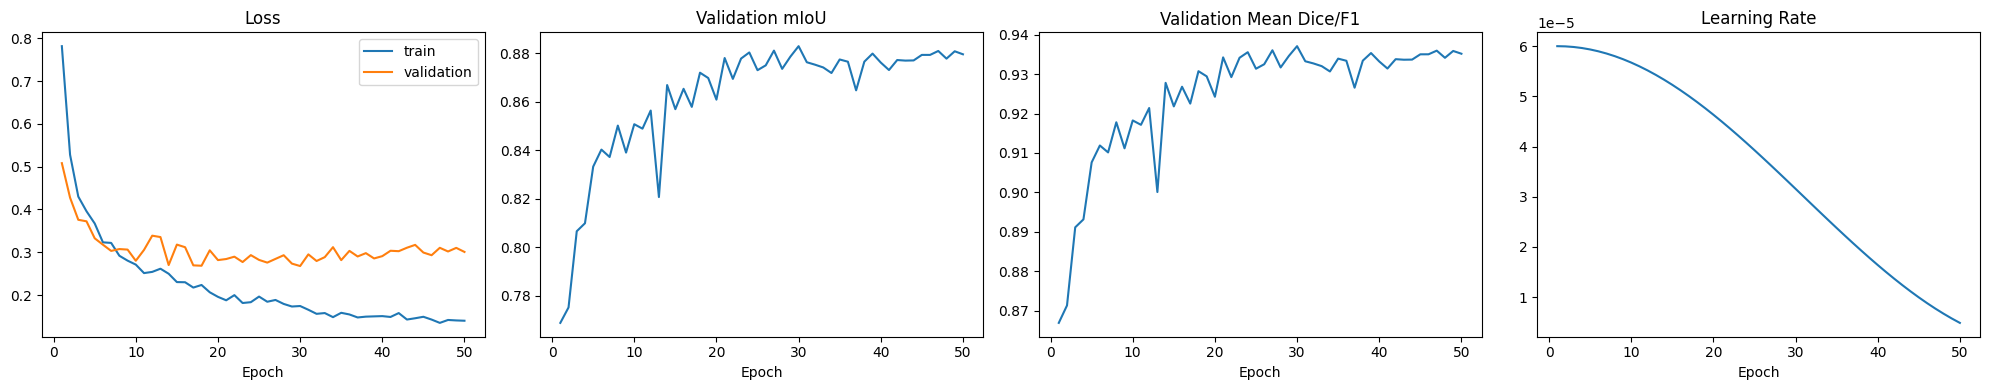

In [7]:
# ============================================================
# TASK E — CELL 6
# Plot training and validation curves
# ============================================================

figure, axes = plt.subplots(
    1,
    4,
    figsize=(
        20,
        4,
    ),
)


axes[0].plot(
    history_df[
        "epoch"
    ],

    history_df[
        "train_loss"
    ],

    label="train",
)


axes[0].plot(
    history_df[
        "epoch"
    ],

    history_df[
        "val_loss"
    ],

    label="validation",
)


axes[0].set_title(
    "Loss"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].legend()


axes[1].plot(
    history_df[
        "epoch"
    ],

    history_df[
        "val_mIoU"
    ],
)

axes[1].set_title(
    "Validation mIoU"
)

axes[1].set_xlabel(
    "Epoch"
)


axes[2].plot(
    history_df[
        "epoch"
    ],

    history_df[
        "val_mean_dice"
    ],
)

axes[2].set_title(
    "Validation Mean Dice/F1"
)

axes[2].set_xlabel(
    "Epoch"
)


axes[3].plot(
    history_df[
        "epoch"
    ],

    history_df[
        "learning_rate"
    ],
)

axes[3].set_title(
    "Learning Rate"
)

axes[3].set_xlabel(
    "Epoch"
)


plt.tight_layout()


plt.savefig(
    OUTPUT_ROOT
    / "segformer_b0_training_curves.png",

    dpi=160,

    bbox_inches="tight",
)


plt.show()

Evaluate test:   0%|          | 0/23 [00:00<?, ?it/s]

Test loss: 0.5441010422176785
{
  "mean_iou": 0.8153945187105519,
  "overall_pixel_accuracy": 0.9115360683865017,
  "mean_pixel_accuracy": 0.8959878693149498,
  "mean_dice": 0.8969482378609164,
  "per_class_iou": {
    "background": 0.8792059069433485,
    "landing_site": 0.7515831304777553
  },
  "per_class_accuracy": {
    "background": 0.9376215790974158,
    "landing_site": 0.8543541595324837
  },
  "per_class_dice": {
    "background": 0.9357206719017125,
    "landing_site": 0.8581758038201204
  }
}


### Overall test metrics

,mIoU,overall_pixel_accuracy,mean_pixel_accuracy,mean_dice_f1
0,0.815395,0.911536,0.895988,0.896948


### Per-class metrics

,class_id,class_name,iou,pixel_accuracy,dice_f1
0,0,background,0.879206,0.937622,0.935721
1,1,landing_site,0.751583,0.854354,0.858176


### Pixel-level confusion matrix

,pred_background,pred_landing_site
true_background,15191252,1010649
true_landing_site,1076477,6314582


### Efficiency metrics for NB3

,total_parameters,trainable_parameters,checkpoint_size_mb,training_time_minutes,test_evaluation_seconds,timed_images,inference_seconds,images_per_second,milliseconds_per_image
0,3714658,3714658,42.767566,15.879911,6.559,312,0.752733,414.489327,2.412607


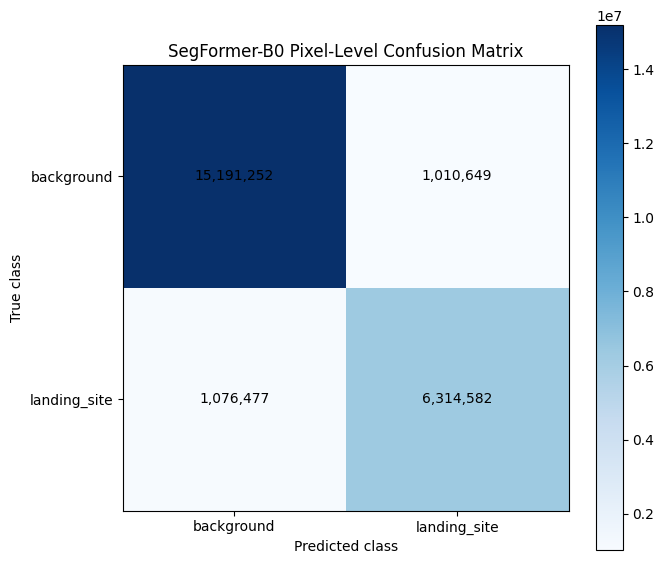

In [8]:
# ============================================================
# TASK F — CELL 7
# Held-out test evaluation and quantitative metrics
# ============================================================

def load_checkpoint(
    path: Path,
):

    try:
        return torch.load(
            path,

            map_location=DEVICE,

            weights_only=False,
        )

    except TypeError:
        return torch.load(
            path,

            map_location=DEVICE,
        )


best_checkpoint = load_checkpoint(
    best_checkpoint_path
)


model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)


model = model.to(
    DEVICE
)

model.eval()


start_test_time = (
    time.time()
)


(
    test_metrics,
    test_loss,
    test_per_image_df,
    test_confusion,
) = evaluate_model(
    model,
    test_loader,
    "test",
)


test_evaluation_seconds = (
    time.time()
    - start_test_time
)


# ------------------------------------------------------------
# Per-class metric table
# ------------------------------------------------------------

per_class_metrics_df = pd.DataFrame(
    [
        {
            "class_id": (
                class_id
            ),

            "class_name": (
                CLASS_ID_TO_NAME[
                    class_id
                ]
            ),

            "iou": (
                test_metrics[
                    "per_class_iou"
                ][
                    CLASS_ID_TO_NAME[
                        class_id
                    ]
                ]
            ),

            "pixel_accuracy": (
                test_metrics[
                    "per_class_accuracy"
                ][
                    CLASS_ID_TO_NAME[
                        class_id
                    ]
                ]
            ),

            "dice_f1": (
                test_metrics[
                    "per_class_dice"
                ][
                    CLASS_ID_TO_NAME[
                        class_id
                    ]
                ]
            ),
        }

        for class_id in range(
            NUM_CLASSES
        )
    ]
)


confusion_df = pd.DataFrame(
    test_confusion,

    index=[
        f"true_"
        f"{CLASS_ID_TO_NAME[index]}"

        for index in range(
            NUM_CLASSES
        )
    ],

    columns=[
        f"pred_"
        f"{CLASS_ID_TO_NAME[index]}"

        for index in range(
            NUM_CLASSES
        )
    ],
)


# ------------------------------------------------------------
# Inference efficiency for NB3 Task H
# ------------------------------------------------------------

@torch.no_grad()
def measure_inference_speed(
    model: nn.Module,
    data_loader: DataLoader,
    warmup_batches: int = 3,
) -> dict:

    model.eval()

    total_images = 0
    total_seconds = 0.0


    for batch_index, (
        images,
        masks,
        _,
    ) in enumerate(
        data_loader
    ):

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True,
        )


        if DEVICE.type == "cuda":
            torch.cuda.synchronize()


        start = (
            time.perf_counter()
        )


        with autocast_context():

            outputs = model(
                pixel_values=images
            )

            logits = resize_logits(
                outputs.logits,
                masks,
            )

            _ = torch.argmax(
                logits,
                dim=1,
            )


        if DEVICE.type == "cuda":
            torch.cuda.synchronize()


        elapsed = (
            time.perf_counter()
            - start
        )


        if batch_index >= warmup_batches:

            total_seconds += (
                elapsed
            )

            total_images += (
                images.shape[0]
            )


    images_per_second = (
        total_images
        / total_seconds

        if total_seconds > 0

        else 0.0
    )


    milliseconds_per_image = (
        1000.0
        / images_per_second

        if images_per_second > 0

        else 0.0
    )


    return {
        "timed_images": int(
            total_images
        ),

        "inference_seconds": float(
            total_seconds
        ),

        "images_per_second": float(
            images_per_second
        ),

        "milliseconds_per_image": float(
            milliseconds_per_image
        ),
    }


speed_metrics = (
    measure_inference_speed(
        model,
        test_loader,
    )
)


checkpoint_size_mb = (
    best_checkpoint_path
    .stat()
    .st_size
    / (1024 ** 2)
)


efficiency_metrics = {
    "total_parameters": int(
        TOTAL_PARAMETERS
    ),

    "trainable_parameters": int(
        TRAINABLE_PARAMETERS
    ),

    "checkpoint_size_mb": float(
        checkpoint_size_mb
    ),

    "training_time_minutes": float(
        training_time_minutes
    ),

    "test_evaluation_seconds": float(
        test_evaluation_seconds
    ),

    **speed_metrics,
}


print(
    "Test loss:",
    test_loss,
)

print(
    json.dumps(
        test_metrics,
        indent=2,
    )
)


display(
    Markdown(
        "### Overall test metrics"
    )
)


display(
    pd.DataFrame(
        [
            {
                "mIoU": (
                    test_metrics[
                        "mean_iou"
                    ]
                ),

                "overall_pixel_accuracy": (
                    test_metrics[
                        "overall_pixel_accuracy"
                    ]
                ),

                "mean_pixel_accuracy": (
                    test_metrics[
                        "mean_pixel_accuracy"
                    ]
                ),

                "mean_dice_f1": (
                    test_metrics[
                        "mean_dice"
                    ]
                ),
            }
        ]
    )
)


display(
    Markdown(
        "### Per-class metrics"
    )
)

display(
    per_class_metrics_df
)


display(
    Markdown(
        "### Pixel-level confusion matrix"
    )
)

display(
    confusion_df
)


display(
    Markdown(
        "### Efficiency metrics for NB3"
    )
)

display(
    pd.DataFrame(
        [
            efficiency_metrics
        ]
    )
)


# ------------------------------------------------------------
# Confusion-matrix plot
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(
        7,
        6,
    )
)


matrix_image = axis.imshow(
    test_confusion,
    cmap="Blues",
)


axis.set_xticks(
    range(
        NUM_CLASSES
    )
)

axis.set_yticks(
    range(
        NUM_CLASSES
    )
)


axis.set_xticklabels(
    [
        CLASS_ID_TO_NAME[index]

        for index in range(
            NUM_CLASSES
        )
    ]
)


axis.set_yticklabels(
    [
        CLASS_ID_TO_NAME[index]

        for index in range(
            NUM_CLASSES
        )
    ]
)


axis.set_xlabel(
    "Predicted class"
)

axis.set_ylabel(
    "True class"
)

axis.set_title(
    "SegFormer-B0 Pixel-Level Confusion Matrix"
)


for row_index in range(
    NUM_CLASSES
):

    for column_index in range(
        NUM_CLASSES
    ):

        axis.text(
            column_index,
            row_index,

            f"{test_confusion[
                row_index,
                column_index
            ]:,}",

            ha="center",
            va="center",
        )


figure.colorbar(
    matrix_image,
    ax=axis,
)


plt.tight_layout()


plt.savefig(
    OUTPUT_ROOT
    / "segformer_b0_confusion_matrix.png",

    dpi=160,

    bbox_inches="tight",
)


plt.show()

,image_id,split,mean_iou,landing_site_iou,background_iou,mean_dice
0,testing_00247,test,0.033276,0.037095,0.029458,0.064383
1,testing_00038,test,0.120329,0.061224,0.179433,0.209827
2,testing_00005,test,0.206905,0.245391,0.168418,0.341181
3,testing_00088,test,0.207199,0.000000,0.414398,0.292986
4,testing_00172,test,0.264381,0.000000,0.528763,0.345876


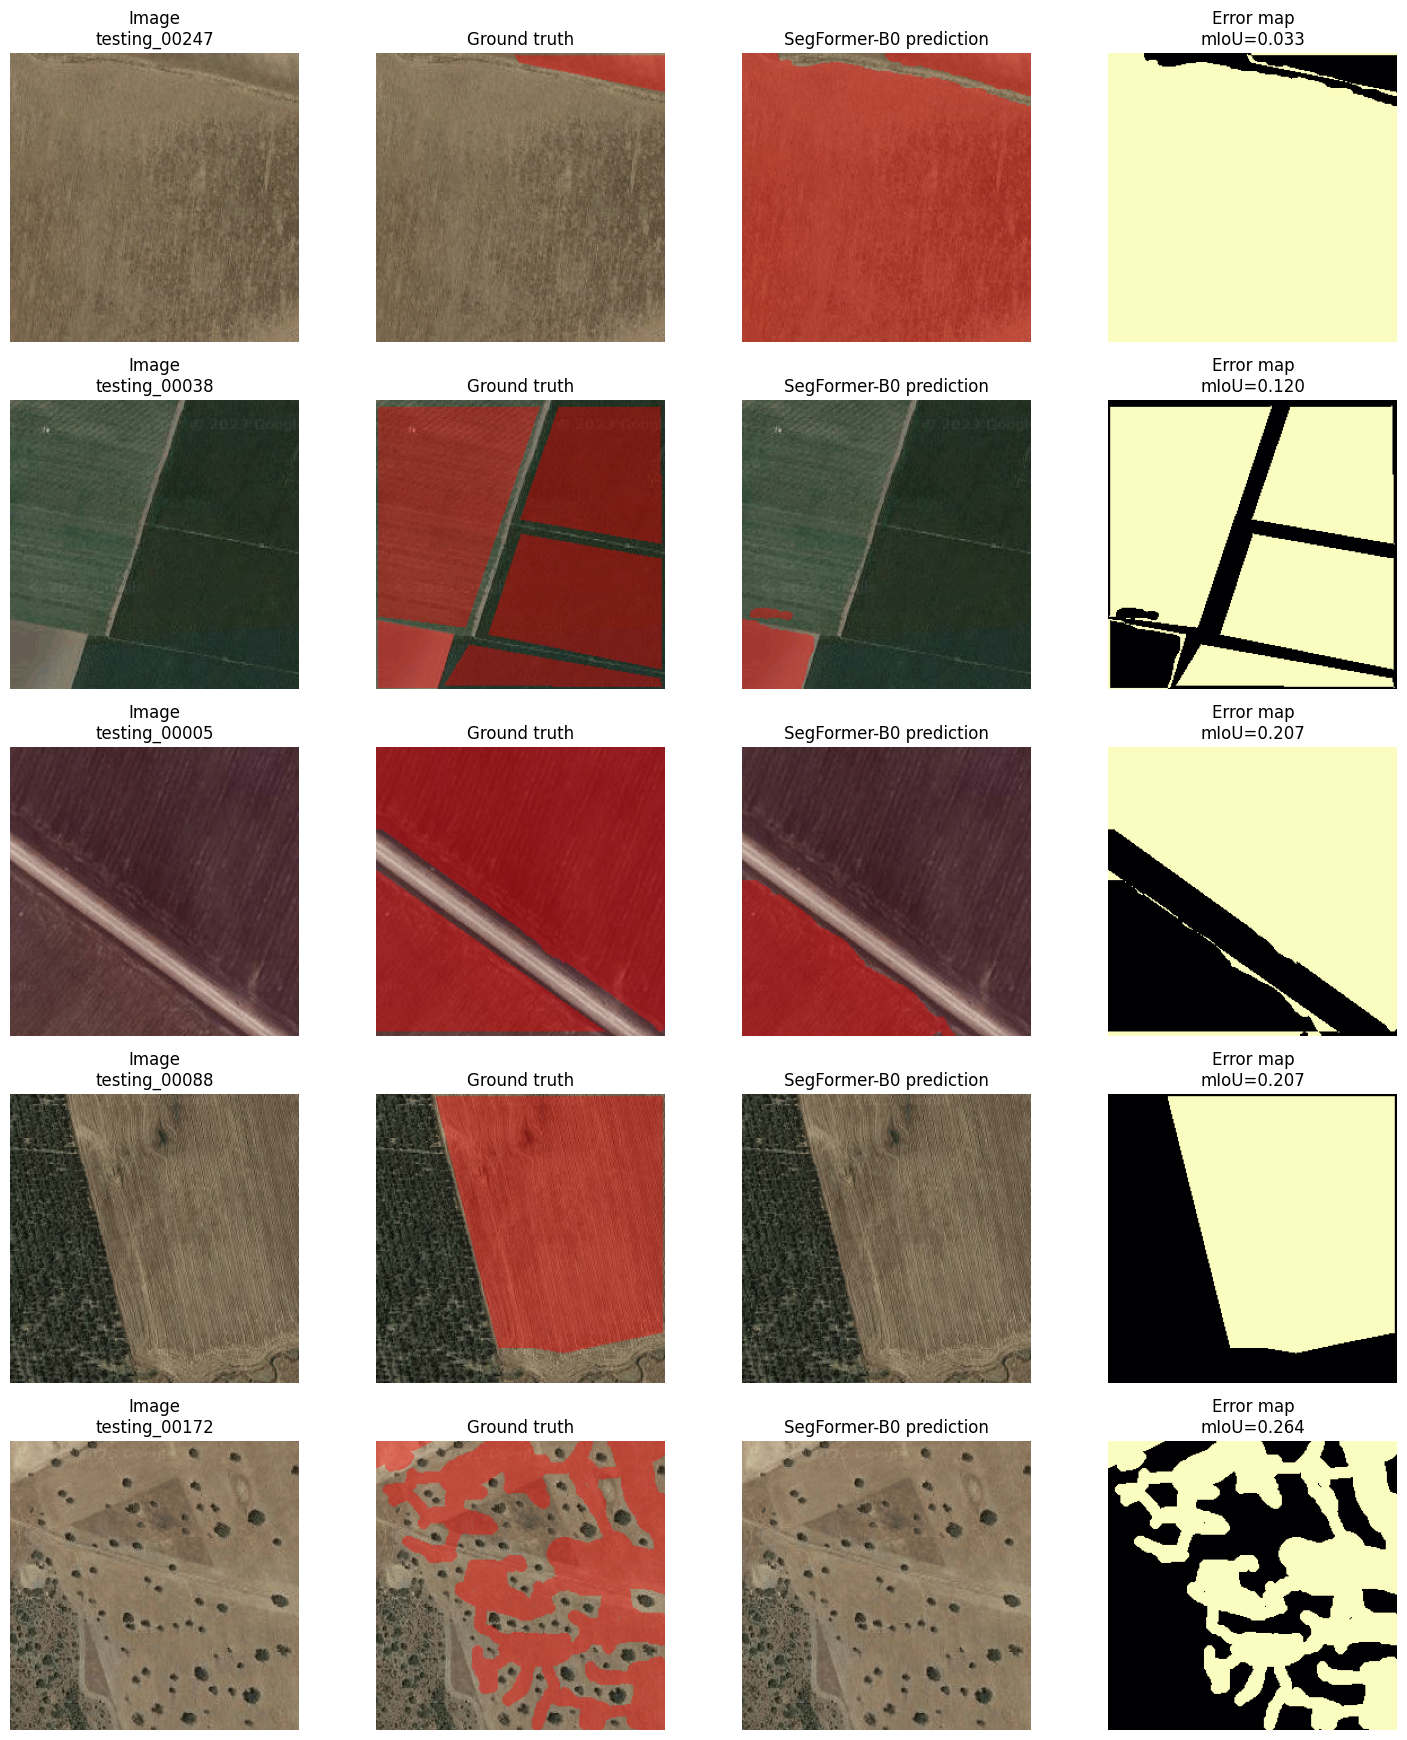

### SegFormer-B0 error analysis

**Worst test image IDs:** testing_00247, testing_00038, testing_00005, testing_00088, testing_00172

- Background → landing-site false positives:
  **1,010,649**

- Landing-site → background false negatives:
  **1,076,477**

False negatives dominate: landing-site pixels are more often predicted as background.

Likely causes include boundary ambiguity, strong class imbalance,
small or thin landing-site regions, and background areas such as
roads or bright open terrain that visually resemble landing sites.

NB3 should compare `segformer_b0_per_image_test_metrics.csv`
with the NB1 and NB3 per-image files to determine whether the
three models fail on the same images.

In [9]:
# ============================================================
# TASK G — CELL 8
# Worst-image visualization and error analysis
# ============================================================

def overlay_mask(
    rgb_image: np.ndarray,
    mask: np.ndarray,
    alpha: float = 0.40,
) -> np.ndarray:

    result = (
        rgb_image.copy()
    )

    red = np.zeros_like(
        result
    )

    red[..., 0] = 1.0

    selected = mask.astype(
        bool
    )

    result[selected] = (
        (1.0 - alpha)
        * result[selected]
        + alpha
        * red[selected]
    )

    return np.clip(
        result,
        0.0,
        1.0,
    )


@torch.no_grad()
def predict_row(
    row: pd.Series,
) -> tuple[
    np.ndarray,
    np.ndarray,
    np.ndarray,
]:

    image_path = (
        DATA_ROOT
        / row[
            "image_relpath"
        ]
    )

    mask_path = (
        NB0_OUTPUT_ROOT
        / row[
            "encoded_mask_relpath"
        ]
    )


    with Image.open(
        image_path
    ) as image_file:

        rgb_uint8 = np.asarray(
            image_file.convert(
                "RGB"
            ),

            dtype=np.uint8,
        )


    ground_truth = load_mask(
        mask_path
    )


    transformed = eval_transform(
        image=rgb_uint8,
        mask=ground_truth,
    )


    image_tensor = (
        transformed[
            "image"
        ]
        .unsqueeze(0)
        .to(DEVICE)
    )


    target_tensor = (
        transformed[
            "mask"
        ]
        .unsqueeze(0)
        .to(DEVICE)
    )


    with autocast_context():

        outputs = model(
            pixel_values=image_tensor
        )

        logits = resize_logits(
            outputs.logits,
            target_tensor,
        )


    prediction = (
        torch.argmax(
            logits,
            dim=1,
        )[0]
        .cpu()
        .numpy()
        .astype(
            np.uint8
        )
    )


    return (
        rgb_uint8.astype(
            np.float32
        ) / 255.0,

        ground_truth,

        prediction,
    )


# ------------------------------------------------------------
# Find five worst test images
# ------------------------------------------------------------

worst_df = (
    test_per_image_df
    .sort_values(
        [
            "mean_iou",
            "landing_site_iou",
        ],

        ascending=True,
    )
    .head(5)
    .reset_index(
        drop=True
    )
)


worst_df.to_csv(
    OUTPUT_ROOT
    / "segformer_b0_worst_test_images.csv",

    index=False,
)


display(
    worst_df
)


figure, axes = plt.subplots(
    len(worst_df),
    4,

    figsize=(
        15,
        3.5
        * len(worst_df),
    ),
)


if len(worst_df) == 1:

    axes = np.expand_dims(
        axes,
        axis=0,
    )


for row_index, metric_row in (
    worst_df.iterrows()
):

    manifest_row = (
        test_df[
            test_df[
                "image_id"
            ]
            == metric_row[
                "image_id"
            ]
        ]
        .iloc[0]
    )


    (
        rgb_image,
        ground_truth,
        prediction,
    ) = predict_row(
        manifest_row
    )


    error_map = (
        ground_truth
        != prediction
    ).astype(
        np.uint8
    )


    axes[
        row_index,
        0,
    ].imshow(
        rgb_image
    )

    axes[
        row_index,
        0,
    ].set_title(
        "Image\n"
        f"{metric_row['image_id']}"
    )


    axes[
        row_index,
        1,
    ].imshow(
        overlay_mask(
            rgb_image,
            ground_truth,
        )
    )

    axes[
        row_index,
        1,
    ].set_title(
        "Ground truth"
    )


    axes[
        row_index,
        2,
    ].imshow(
        overlay_mask(
            rgb_image,
            prediction,
        )
    )

    axes[
        row_index,
        2,
    ].set_title(
        "SegFormer-B0 prediction"
    )


    axes[
        row_index,
        3,
    ].imshow(
        error_map,

        cmap="magma",

        vmin=0,

        vmax=1,
    )

    axes[
        row_index,
        3,
    ].set_title(
        "Error map\n"
        f"mIoU="
        f"{metric_row['mean_iou']:.3f}"
    )


    for column_index in range(
        4
    ):

        axes[
            row_index,
            column_index,
        ].axis(
            "off"
        )


plt.tight_layout()


plt.savefig(
    OUTPUT_ROOT
    / "segformer_b0_worst_examples.png",

    dpi=160,

    bbox_inches="tight",
)


plt.show()


# ------------------------------------------------------------
# Confusion discussion
# ------------------------------------------------------------

false_positive_pixels = int(
    test_confusion[
        0,
        1,
    ]
)


false_negative_pixels = int(
    test_confusion[
        1,
        0,
    ]
)


if (
    false_negative_pixels
    > false_positive_pixels
):

    dominant_error = (
        "False negatives dominate: landing-site pixels "
        "are more often predicted as background."
    )


elif (
    false_positive_pixels
    > false_negative_pixels
):

    dominant_error = (
        "False positives dominate: background pixels "
        "are more often predicted as landing site."
    )


else:

    dominant_error = (
        "False positives and false negatives are balanced."
    )


worst_image_ids = (
    worst_df[
        "image_id"
    ].tolist()
)


error_analysis_text = f"""
### SegFormer-B0 error analysis

**Worst test image IDs:** {", ".join(worst_image_ids)}

- Background → landing-site false positives:
  **{false_positive_pixels:,}**

- Landing-site → background false negatives:
  **{false_negative_pixels:,}**

{dominant_error}

Likely causes include boundary ambiguity, strong class imbalance,
small or thin landing-site regions, and background areas such as
roads or bright open terrain that visually resemble landing sites.

NB3 should compare `segformer_b0_per_image_test_metrics.csv`
with the NB1 and NB3 per-image files to determine whether the
three models fail on the same images.
"""


error_analysis_text = (
    textwrap.dedent(
        error_analysis_text
    ).strip()
)


with (
    OUTPUT_ROOT
    / "segformer_b0_error_analysis.md"
).open(
    "w",
    encoding="utf-8",
) as file:

    file.write(
        error_analysis_text
        + "\n"
    )


with (
    OUTPUT_ROOT
    / "segformer_b0_error_summary.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        {
            "model": "SegFormer-B0",

            "worst_image_ids": (
                worst_image_ids
            ),

            "false_positive_pixels": (
                false_positive_pixels
            ),

            "false_negative_pixels": (
                false_negative_pixels
            ),

            "dominant_error": (
                dominant_error
            ),
        },

        file,

        indent=2,
    )


display(
    Markdown(
        error_analysis_text
    )
)

In [10]:
# ============================================================
# NB3 HANDOFF — CELL 9
# Save metrics, per-image results and fixed predictions
# ============================================================

metrics_payload = {
    "notebook": "NB2",

    "model": "SegFormer-B0",

    "dataset": (
        "Moroccan Landing Site "
        "Segmentation V2"
    ),

    "split_source": str(
        SPLIT_FILE
    ),

    "split_sha256": (
        SPLIT_SHA256
    ),

    "nb0_output_root": str(
        NB0_OUTPUT_ROOT
    ),

    "pretrained_checkpoint": (
        CONFIG[
            "pretrained_checkpoint"
        ]
    ),

    "resolved_model_source": (
        MODEL_SOURCE
    ),

    "best_epoch": int(
        best_epoch
    ),

    "trained_epochs": int(
        actual_trained_epochs
    ),

    "test_loss": float(
        test_loss
    ),

    "metrics": (
        test_metrics
    ),

    "confusion_matrix": (
        test_confusion
        .astype(int)
        .tolist()
    ),

    "class_names": (
        CLASS_ID_TO_NAME
    ),

    "efficiency": (
        efficiency_metrics
    ),

    "config": (
        CONFIG
    ),

    "saved_at": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),
}


with (
    OUTPUT_ROOT
    / "segformer_b0_metrics.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        metrics_payload,
        file,
        indent=2,
    )


per_class_metrics_df.to_csv(
    OUTPUT_ROOT
    / "segformer_b0_per_class_metrics.csv",

    index=False,
)


test_per_image_df.to_csv(
    OUTPUT_ROOT
    / "segformer_b0_per_image_test_metrics.csv",

    index=False,
)


confusion_df.to_csv(
    OUTPUT_ROOT
    / "segformer_b0_confusion_matrix.csv",
)


# ------------------------------------------------------------
# Use NB0's fixed qualitative sample IDs
# ------------------------------------------------------------

with COMPARISON_IDS_FILE.open(
    "r",
    encoding="utf-8",
) as file:

    comparison_ids = json.load(
        file
    )[
        "sample_ids"
    ]


if len(comparison_ids) < 5:

    raise RuntimeError(
        "NB0 comparison_sample_ids.json "
        "needs at least five IDs."
    )


comparison_ids = (
    comparison_ids[:5]
)


comparison_directory = (
    OUTPUT_ROOT
    / "comparison_predictions"
)


comparison_directory.mkdir(
    parents=True,
    exist_ok=True,
)


saved_prediction_rows = []


for image_id in comparison_ids:

    matching_rows = (
        test_df[
            test_df[
                "image_id"
            ] == image_id
        ]
    )


    if matching_rows.empty:

        raise RuntimeError(
            "Comparison ID is not in "
            f"the test split: {image_id}"
        )


    manifest_row = (
        matching_rows.iloc[0]
    )


    (
        rgb_image,
        ground_truth,
        prediction,
    ) = predict_row(
        manifest_row
    )


    prediction_path = (
        comparison_directory
        / (
            f"{image_id}"
            "_segformer_b0_pred.png"
        )
    )


    overlay_path = (
        comparison_directory
        / (
            f"{image_id}"
            "_segformer_b0_overlay.png"
        )
    )


    Image.fromarray(
        prediction.astype(
            np.uint8
        )
    ).save(
        prediction_path
    )


    Image.fromarray(
        (
            overlay_mask(
                rgb_image,
                prediction,
            )
            * 255.0
        ).astype(
            np.uint8
        )
    ).save(
        overlay_path
    )


    saved_prediction_rows.append(
        {
            "image_id": image_id,

            "prediction_relpath": (
                prediction_path
                .relative_to(
                    OUTPUT_ROOT
                )
                .as_posix()
            ),

            "overlay_relpath": (
                overlay_path
                .relative_to(
                    OUTPUT_ROOT
                )
                .as_posix()
            ),
        }
    )


comparison_predictions_df = (
    pd.DataFrame(
        saved_prediction_rows
    )
)


comparison_predictions_df.to_csv(
    OUTPUT_ROOT
    / "segformer_b0_comparison_predictions.csv",

    index=False,
)


# ------------------------------------------------------------
# Shared result entry for NB3
# ------------------------------------------------------------

results_payload = {
    "schema_version": 1,

    "dataset": (
        "Moroccan Landing Site "
        "Segmentation V2"
    ),

    "split_sha256": (
        SPLIT_SHA256
    ),

    "models": {
        "SegFormer-B0": {
            "notebook": "NB2",

            "metrics_file": (
                "segformer_b0_metrics.json"
            ),

            "per_image_file": (
                "segformer_b0_per_image_test_metrics.csv"
            ),

            "comparison_file": (
                "segformer_b0_comparison_predictions.csv"
            ),

            "best_epoch": int(
                best_epoch
            ),

            "trained_epochs": int(
                actual_trained_epochs
            ),

            "metrics": (
                test_metrics
            ),

            "efficiency": (
                efficiency_metrics
            ),
        }
    },
}


with (
    OUTPUT_ROOT
    / "results.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        results_payload,
        file,
        indent=2,
    )


print(
    "NB2 metrics and fixed comparison "
    "predictions saved for NB3."
)


display(
    comparison_predictions_df
)

NB2 metrics and fixed comparison predictions saved for NB3.


,image_id,prediction_relpath,overlay_relpath
0,testing_00004,comparison_predictions/testing_00004_segformer...,comparison_predictions/testing_00004_segformer...
1,testing_00086,comparison_predictions/testing_00086_segformer...,comparison_predictions/testing_00086_segformer...
2,testing_00058,comparison_predictions/testing_00058_segformer...,comparison_predictions/testing_00058_segformer...
3,testing_00006,comparison_predictions/testing_00006_segformer...,comparison_predictions/testing_00006_segformer...
4,testing_00352,comparison_predictions/testing_00352_segformer...,comparison_predictions/testing_00352_segformer...


In [11]:
# ============================================================
# NB2 — CELL 10
# Final summary and output verification
# ============================================================

summary_text = f"""
## NB2 — SegFormer-B0 final summary

- Shared NB0 split: **1416 train / 314 validation / 360 test**
- Split SHA-256: `{SPLIT_SHA256}`
- Model: **SegFormer-B0 with MiT-B0 encoder**
- Checkpoint: `{CONFIG['pretrained_checkpoint']}`
- Loss: **weighted cross-entropy + Dice loss**
- Optimizer: **AdamW**
- Trained epochs: **{actual_trained_epochs}**
- Best epoch: **{best_epoch}**
- Training time: **{training_time_minutes:.2f} minutes**

### Held-out test results

- mIoU: **{test_metrics['mean_iou']:.6f}**
- Overall pixel accuracy:
  **{test_metrics['overall_pixel_accuracy']:.6f}**
- Mean pixel accuracy:
  **{test_metrics['mean_pixel_accuracy']:.6f}**
- Mean Dice/F1:
  **{test_metrics['mean_dice']:.6f}**
- Background IoU:
  **{test_metrics['per_class_iou']['background']:.6f}**
- Landing-site IoU:
  **{test_metrics['per_class_iou']['landing_site']:.6f}**

NB3 should attach the outputs of NB0, NB1 and NB2 and load:

- `segformer_b0_metrics.json`
- `segformer_b0_per_image_test_metrics.csv`
- `segformer_b0_comparison_predictions.csv`
- `results.json`
"""


summary_text = (
    textwrap.dedent(
        summary_text
    ).strip()
)


with (
    OUTPUT_ROOT
    / "segformer_b0_summary.md"
).open(
    "w",
    encoding="utf-8",
) as file:

    file.write(
        summary_text
        + "\n"
    )


display(
    Markdown(
        summary_text
    )
)


required_outputs = [
    OUTPUT_ROOT
    / "segformer_b0_best.pth",

    OUTPUT_ROOT
    / "segformer_b0_last.pth",

    OUTPUT_ROOT
    / "segformer_b0_config.json",

    OUTPUT_ROOT
    / "segformer_b0_training_history.csv",

    OUTPUT_ROOT
    / "segformer_b0_training_curves.png",

    OUTPUT_ROOT
    / "segformer_b0_metrics.json",

    OUTPUT_ROOT
    / "segformer_b0_per_class_metrics.csv",

    OUTPUT_ROOT
    / "segformer_b0_per_image_test_metrics.csv",

    OUTPUT_ROOT
    / "segformer_b0_confusion_matrix.csv",

    OUTPUT_ROOT
    / "segformer_b0_confusion_matrix.png",

    OUTPUT_ROOT
    / "segformer_b0_worst_test_images.csv",

    OUTPUT_ROOT
    / "segformer_b0_worst_examples.png",

    OUTPUT_ROOT
    / "segformer_b0_error_analysis.md",

    OUTPUT_ROOT
    / "segformer_b0_error_summary.json",

    OUTPUT_ROOT
    / "segformer_b0_comparison_predictions.csv",

    OUTPUT_ROOT
    / "segformer_b0_summary.md",

    OUTPUT_ROOT
    / "results.json",
]


for output_path in (
    required_outputs
):

    if not output_path.exists():

        raise FileNotFoundError(
            "Missing NB2 output: "
            f"{output_path}"
        )


if actual_trained_epochs < 50:

    raise RuntimeError(
        "Assignment requires at least "
        "50 training epochs."
    )


print(
    "NB2_outputs/"
)


for path in sorted(
    OUTPUT_ROOT.rglob("*")
):

    print(
        " -",
        path.relative_to(
            OUTPUT_ROOT
        ),
    )


print(
    "\nFinal checks passed:"
)

print(
    "✓ Exact NB0 split reused"
)

print(
    "✓ SegFormer-B0 / MiT-B0 used"
)

print(
    "✓ Minimum 50 epochs completed"
)

print(
    "✓ Task F metrics saved"
)

print(
    "✓ Task G error analysis saved"
)

print(
    "✓ Fixed predictions saved for NB3"
)

print(
    "\nNB2 completed successfully."
)

## NB2 — SegFormer-B0 final summary

- Shared NB0 split: **1416 train / 314 validation / 360 test**
- Split SHA-256: `1867384ab21b0acbedb0b96721d42355ee6a55e56a2874bf52e9b628264b0d59`
- Model: **SegFormer-B0 with MiT-B0 encoder**
- Checkpoint: `nvidia/segformer-b0-finetuned-ade-512-512`
- Loss: **weighted cross-entropy + Dice loss**
- Optimizer: **AdamW**
- Trained epochs: **50**
- Best epoch: **30**
- Training time: **15.88 minutes**

### Held-out test results

- mIoU: **0.815395**
- Overall pixel accuracy:
  **0.911536**
- Mean pixel accuracy:
  **0.895988**
- Mean Dice/F1:
  **0.896948**
- Background IoU:
  **0.879206**
- Landing-site IoU:
  **0.751583**

NB3 should attach the outputs of NB0, NB1 and NB2 and load:

- `segformer_b0_metrics.json`
- `segformer_b0_per_image_test_metrics.csv`
- `segformer_b0_comparison_predictions.csv`
- `results.json`

NB2_outputs/
 - comparison_predictions
 - comparison_predictions/testing_00004_segformer_b0_overlay.png
 - comparison_predictions/testing_00004_segformer_b0_pred.png
 - comparison_predictions/testing_00006_segformer_b0_overlay.png
 - comparison_predictions/testing_00006_segformer_b0_pred.png
 - comparison_predictions/testing_00058_segformer_b0_overlay.png
 - comparison_predictions/testing_00058_segformer_b0_pred.png
 - comparison_predictions/testing_00086_segformer_b0_overlay.png
 - comparison_predictions/testing_00086_segformer_b0_pred.png
 - comparison_predictions/testing_00352_segformer_b0_overlay.png
 - comparison_predictions/testing_00352_segformer_b0_pred.png
 - results.json
 - segformer_b0_best.pth
 - segformer_b0_comparison_predictions.csv
 - segformer_b0_config.json
 - segformer_b0_confusion_matrix.csv
 - segformer_b0_confusion_matrix.png
 - segformer_b0_error_analysis.md
 - segformer_b0_error_summary.json
 - segformer_b0_last.pth
 - segformer_b0_metrics.json
 - segformer_b0_p